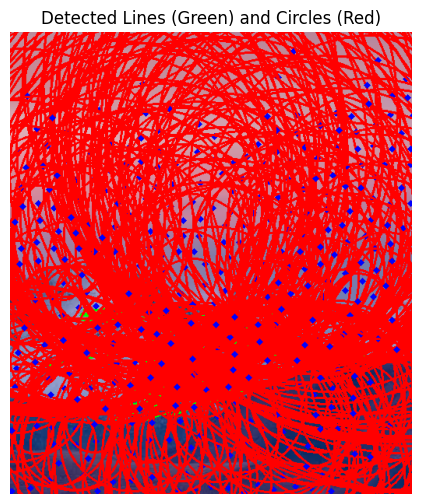

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


# Function to Display Images
def show_image(title, img):
    plt.figure(figsize=(8, 6))
    plt.title(title)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.show()
# 1. Load Image
img = cv2.imread('/content/drive/MyDrive/COMPUTER VISION/images013.jpg')

# Check whether image is loaded
if img is None:
    raise FileNotFoundError("Image not found. Check the image filename and path.")

output = img.copy()

# 2. Convert Image to Grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)


# --------------------------------------------------
# PART A: LINE DETECTION USING HOUGH TRANSFORM
# --------------------------------------------------

# 3. Edge Detection using Canny
edges = cv2.Canny(
    gray,
    50,
    150,
    apertureSize=3
)

# 4. Detect Lines using Probabilistic Hough Transform
lines = cv2.HoughLinesP(
    edges,
    1,
    np.pi / 180,
    100,
    minLineLength=100,
    maxLineGap=10
)

# 5. Draw Detected Lines
if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = line[0]

        # Draw green lines
        cv2.line(
            output,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )


# --------------------------------------------------
# PART B: CIRCLE DETECTION USING HOUGH TRANSFORM
# --------------------------------------------------

# 6. Apply Median Blur to Reduce Noise
gray_blurred = cv2.medianBlur(gray, 5)

# 7. Detect Circles using Hough Circle Transform
circles = cv2.HoughCircles(
    gray_blurred,
    cv2.HOUGH_GRADIENT,
    1,
    20,
    param1=50,
    param2=30,
    minRadius=0,
    maxRadius=0
)

# 8. Draw Detected Circles
if circles is not None:

    circles = np.uint16(np.around(circles))

    for circle in circles[0, :]:

        # Extract circle coordinates and radius
        x, y, r = circle

        # Draw outer circle in red
        cv2.circle(
            output,
            (x, y),
            r,
            (0, 0, 255),
            2
        )

        # Draw circle center in blue
        cv2.circle(
            output,
            (x, y),
            2,
            (255, 0, 0),
            3
        )


# --------------------------------------------------
#  PART C: DISPLAY FINAL RESULT
# --------------------------------------------------

show_image(
    "Detected Lines (Green) and Circles (Red)",
    output
)